In [115]:
import os, re, sys, json, time, ast, operator, subprocess
from pathlib import Path
from dataclasses import dataclass, field
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field, ValidationError
from dotenv import load_dotenv
from ddgs import DDGS
from trafilatura import extract


load_dotenv(dotenv_path=Path.cwd().parent / ".env")

OPENROUTER_API_KEY = os.getenv("OPENROUTER_API_KEY")
if not OPENROUTER_API_KEY:
    raise ValueError("API key not found.")

CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
HEADERS = {"Authorization": f"Bearer {OPENROUTER_API_KEY}",
           "HTTP-Referer": "https://postypashki.ru", "X-Title": "agents-course-seminar01"}
MODELS = {"cheap": "openai/gpt-4o-mini", "mid": "anthropic/claude-haiku-4.5", "strong": "anthropic/claude-sonnet-4.6"}
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
DATA = Path.cwd().parent / "data"
TRACES, IMG = Path.cwd().parent / "traces", Path.cwd().parent / "img"
TRACES.mkdir(exist_ok=True)
IMG.mkdir(exist_ok=True)

In [70]:
@dataclass
class Ledger:
    calls: list = field(default_factory=list)

    def add(self, tag, model, usage, seconds=0.0):
        p, c = usage.get("prompt_tokens", 0), usage.get("completion_tokens", 0)
        cost = usage.get("cost") or 0.0
        self.calls.append({"tag": tag, "model": model.split("/")[-1], "prompt": p, "completion": c,
                           "cost": cost, "seconds": round(seconds, 2)})
        return cost

    @property
    def total(self):
        return sum(c["cost"] for c in self.calls)

    def table(self):
        df = pd.DataFrame(self.calls)
        return df.groupby(["tag", "model"]).agg(calls=("cost", "size"), prompt=("prompt", "sum"),
                                                completion=("completion", "sum"), cost=("cost", "sum"),
                                                seconds=("seconds", "sum")).round(5)

ledger = Ledger()

In [71]:
def post_with_retry(body, attempts=3):
    for attempt in range(attempts):
        r = requests.post(CHAT_URL, json=body, headers=HEADERS, timeout=120)
        if r.status_code == 200:
            return r.json()
        if r.status_code in (429, 500, 502, 503) and attempt < attempts - 1:
            time.sleep(1.5 * (attempt+1))
            continue
        raise RuntimeError(f"HTTP {r.status_code} : {r.text[:5000]}")

In [72]:
def chat(messages, model, tools=None, tag="chat", temperature=None):
    body = {"model": model, "messages": messages, "usage": {"include": True}}
    if tools:
        body["tools"] = tools
        body["tool_choice"] = "auto"
    if temperature is not None:
        body["temperature"] = temperature
    started = time.perf_counter()
    data = post_with_retry(body)
    ledger.add(tag, model, data.get("usage") or {}, time.perf_counter() - started)
    return data["choices"][0]["message"]

In [73]:
class Answer(BaseModel):
    reasoning: str = Field(description="ход решения в два-три предложения")
    final: str = Field(description="только итоговый ответ: число или короткая фраза")

SCHEMA_PROMPT = "Отвечай строго одним JSON-объектом по этой схеме, без текста вокруг, строки в одну линию, без лишних отступов, \t, \n:\n{schema}"

def json_from(text):
    m = re.search(r"\{.*\}", text or "", re.S)
    if not m:
        raise ValueError("в ответе нет JSON")
    return json.loads(m.group(0), strict=False)

In [74]:
schema=Answer
SCHEMA_PROMPT.format(schema=json.dumps(schema.model_json_schema(), ensure_ascii=False))

'Отвечай строго одним JSON-объектом по этой схеме, без текста вокруг, строки в одну линию, без лишних отступов, \t, \n:\n{"properties": {"reasoning": {"description": "ход решения в два-три предложения", "title": "Reasoning", "type": "string"}, "final": {"description": "только итоговый ответ: число или короткая фраза", "title": "Final", "type": "string"}}, "required": ["reasoning", "final"], "title": "Answer", "type": "object"}'

In [75]:
def ask_structured(question, model, schema=Answer, attempts=3):
    messages = [
        {"role": "system", "content": SCHEMA_PROMPT.format(schema=json.dumps(schema.model_json_schema(), ensure_ascii=False))},
        {"role": "user", "content": question}
    ]
    for _ in range(attempts):
        msg = chat(messages, model, tag="struct")
        try:
            return schema.model_validate(json_from(msg["content"]))
        except (ValidationError, ValueError) as e:
            messages += [msg, {"role": "user", "content": f"Ответ не прошел проверку на структуру: {e}. Верни ответ по строгой JSON схеме"}]
    raise ValueError("Модель не справилась")

In [76]:
def load_tasks(name):
    return [json.loads(line) for line in (DATA / name).read_text(encoding="utf-8").splitlines() if line.strip()]

In [77]:
task = load_tasks("fresh_custom_2026.jsonl")[0]
ans = ask_structured(task["question"], MODELS["cheap"])
ans, task["answer"]

(Answer(reasoning='The 2026 Australian Grand Prix has not yet taken place as it is scheduled for the future. Therefore, a winner cannot be determined at this time.', final='Unknown'),
 'George Russell')

In [78]:
class Numeric(BaseModel):
    final: float = Field(description="ответ числом")

calls_before = len(ledger.calls)
try:
    result = ask_structured("Какой год основания франции", MODELS["cheap"], Numeric)
except ValueError as e:
    result = e
print("вызовов потрачено:", len(ledger.calls) - calls_before, "| результат:", result)

вызовов потрачено: 1 | результат: final=843.0


In [79]:
def normalize(text):
    text = re.sub(r"[^\w\s]", " ", str(text).lower().replace(",", ""))
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())

def is_correct(task, answer):
    if task["source"] == "gsm8k":
        nums = re.findall(r"-?\d+(?:\.\d+)?", str(answer).replace(",", ""))
        return bool(nums) and abs(float(nums[-1]) - float(task["answer"])) < 1e-6
    return normalize(task["answer"]) in normalize(answer)

def summary(config, model, n, correct, cost, steps, seconds=0.0):
    return {"config": config, "model": model.split("/")[-1], "n": n, "accuracy": round(correct / n, 2),
            "cost_per_task": round(cost / n, 5), "cost_per_correct": round(cost / correct, 5) if correct else float("inf"),
            "avg_steps": round(steps, 2), "avg_seconds": round(seconds, 1)}

def compare_models(tasks, models):
    rows = []
    for name, model in models.items():
        before, correct, started = ledger.total, 0, time.perf_counter()
        for task in tasks:
            try:
                correct += is_correct(task, ask_structured(task["question"], model).final)
            except Exception:
                pass
        rows.append(summary("без инструментов, JSON", model, len(tasks), correct, ledger.total - before, 1,
                            (time.perf_counter() - started) / len(tasks)))
    return pd.DataFrame(rows)

def compare_chart(df):
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
    axes[0].bar(df["model"], df["accuracy"] * 100, color=COLORS["violet"])
    axes[0].set_ylabel("доля верных, %")
    axes[0].set_ylim(0, 105)
    axes[1].bar(df["model"], df["cost_per_correct"] * 100, color=COLORS["amber"])
    axes[1].set_ylabel("цена верного ответа, центы")
    axes[2].bar(df["model"], df["avg_seconds"], color=COLORS["teal"])
    axes[2].set_ylabel("секунд на задачу")
    for ax in axes:
        ax.tick_params(axis="x", labelrotation=12)
        ax.grid(alpha=0.3, axis="y")
    fig.tight_layout()
    return fig

In [80]:
TOOLS = {}

def register(fn, args_model, description):
    TOOLS[fn.__name__] = {"fn": fn, "args": args_model, "schema": {"type": "function", "function": {
        "name": fn.__name__, "description": description, "parameters": args_model.model_json_schema()}}}

OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv,
       ast.Pow: operator.pow, ast.USub: operator.neg, ast.Mod: operator.mod}

def evaluate(node):
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in OPS:
        return OPS[type(node.op)](evaluate(node.left), evaluate(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in OPS:
        return OPS[type(node.op)](evaluate(node.operand))
    raise ValueError("допустимы только числа и арифметика")

class CalcArgs(BaseModel):
    expr: str = Field(description="арифметическое выражение, например 17*23+5")

def calculator(expr: str) -> str:
    try:
        val = evaluate(ast.parse(expr.replace(",", "."), mode="eval").body)
        return str(int(val)) if float(val).is_integer() else f"{val:.4f}".rstrip("0")
    except Exception as e:
        return f"ошибка вычисления: {e}"

register(calculator, CalcArgs, "Считает арифметическое выражение: числа, скобки, + - * / ** %")
json.dumps(TOOLS["calculator"]["schema"], ensure_ascii=False, indent=1)

'{\n "type": "function",\n "function": {\n  "name": "calculator",\n  "description": "Считает арифметическое выражение: числа, скобки, + - * / ** %",\n  "parameters": {\n   "properties": {\n    "expr": {\n     "description": "арифметическое выражение, например 17*23+5",\n     "title": "Expr",\n     "type": "string"\n    }\n   },\n   "required": [\n    "expr"\n   ],\n   "title": "CalcArgs",\n   "type": "object"\n  }\n }\n}'

In [81]:
SYSTEM = ("Ты решаешь задачи. Если нужно посчитать или найти факт, вызывай инструменты, а не угадывай. "
          "Когда ответ готов, напиши его последней строкой в формате FINAL: <ответ>. "
          "Для числовых задач в FINAL только число, для вопросов о фактах короткая фраза.")

@dataclass
class Run:
    question: str
    answer: str
    steps: int
    messages: list
    cost: float = 0.0
    seconds: float = 0.0

def looped(seen, calls):
    keys = [(c["function"]["name"], c["function"]["arguments"]) for c in calls]
    repeated = any(k in seen for k in keys)
    seen.update(keys)
    return repeated

def finish(model, messages, step):
    del messages[-1]
    messages.append({"role": "user", "content": "Инструменты больше недоступны. Ответь по тому, что уже известно, последней строкой FINAL: <ответ>."})
    msg = chat(messages, model, tag="agent")
    messages.append(msg)
    return msg.get("content") or "", step + 1

In [135]:
def run_tool(call):
    name = call["function"]["name"]

    try:
        spec = TOOLS[name]
        args = spec["args"].model_validate_json(call["function"]["arguments"])
        result = spec["fn"](**args.model_dump())
    except Exception as e:
        result = f"НЕ удалось вызвать инструмент {name}: {e}"
    return {"role": "tool", "tool_call_id" : call["id"], "content": str(result)[:5000]}


In [83]:
def agent_loop(messages, model, tool_names, max_steps):
    seen = set()
    for step in range(1, max_steps + 1):
        msg = chat(messages, model, tools=[TOOLS[n]["schema"] for n in tool_names] or None, tag='agent')
        messages.append(msg)
        calls = msg.get("tool_calls") or []

        if not calls:
            return msg.get("content") or "", step
        if looped(seen, calls) or step == max_steps:
            return finish(model, messages, step)

        messages += [run_tool(c) for c in calls]


In [84]:
def agent(question, model, tool_names, max_steps=8):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    before, started = ledger.total, time.perf_counter()
    answer, steps = agent_loop(messages, model, tool_names, max_steps)
    return Run(question, answer, steps, messages, ledger.total - before, time.perf_counter() - started)

def show_trace(run):
    for m in run.messages[1:]:
        calls = "; ".join(f"{c['function']['name']}{c['function']['arguments']}" for c in m.get("tool_calls") or [])
        text = " ".join((m.get("content") or "").split())[:180]
        print(f"{m['role']:9s}| {text} {calls}")
    print(f"шагов: {run.steps}, цена: {run.cost * 100:.3f} ¢, время: {run.seconds:.1f} c")

In [169]:
WIKI = "https://en.wikipedia.org/w/api.php"
WIKI_HEADERS = {"User-Agent": "agents-course-seminar01/1.0 (https://postypashki.ru; educational project)"}

def wiki(params, attempts=3):
    for attempt in range(attempts):
        r = requests.get(WIKI, params={**params, "format": "json"}, headers=WIKI_HEADERS, timeout=15)
        if r.status_code == 200 and r.headers.get("content-type", "").startswith("application/json"):
            return r.json()["query"]
        time.sleep(1.0 + attempt)
    raise RuntimeError(f"Википедия ответила {r.status_code}")

class SearchArgs(BaseModel):
    query: str = Field(description="короткий поисковый запрос: имя, название, термин")

class ReadPageArgs(BaseModel):
    url: str = Field(description="URL веб-страницы для чтения")
    keywords: str | None = Field(default=None, description="ключевые слова для поиска в тексте страницы")

class ExecArgs(BaseModel):
    code: str = Field(description="код на Python; результат надо напечатать через print")

In [170]:
def ddg_search(query: str) -> str:
        try:
            result = DDGS(timeout=15).text(query, max_results=3)
            if not result:
                return "No data"
            return "\n\n".join(
                        f"{i}. {item['title']}\nURL: {item['href']}\n{item['body']}"
                        for i, item in enumerate(result, start=1)
                    )
        except Exception as e:
            return f"ошибка поиска: {e}"

def read_page(url: str, keywords: str | None = None) -> str:
    try:
        response = requests.get(url, headers={"User-Agent" : "https://github.com/Dravner/PP/tree/sem1"}, timeout=15)
        response.raise_for_status()
    except Exception as e:
        return f"ошибка загрузки страницы: {e}"

    try:
        text = extract(response.text, include_comments=False, include_tables=True)
    except Exception as e:
        return f"ошибка извлечения текста: {e}"

    if not text:
        return "Не удалось извлечь текст страницы"
    if keywords:
        words = keywords.casefold().split()
        text = "\n".join(
            line for line in text.splitlines()
            if any(word in line.casefold() for word in words)
        )
    return text[:5000]

def python_exec(code: str) -> str:
    try:
        r = subprocess.run([sys.executable, "-I", "-c", code], capture_output=True, text=True, timeout=5)
    except subprocess.TimeoutExpired:
        return "Код превысил 5 сек"
    out = (r.stdout + r.stderr).strip()
    return out[:5000] if out else "Код исполнился но результат пустой"

In [171]:
register(ddg_search, SearchArgs, "Ищет статьи и возвращает их заголовки и ссылки")
register(read_page, ReadPageArgs, "Читает содержимое веб-страницы по URL и возвращает его, можно указать ключевые слова для фильтрации")
register(python_exec, ExecArgs, "Выполняет код на Python в отдельном процессе и возвращает то, что он напечатал")


In [ ]:
ddg_search("Кто победил на гран при Сепанга 2026?")

In [165]:
read_page("https://ru.wikipedia.org/wiki/Гран-при_Бахрейна_2026_года", "победитель, Гран-при Сепанга 2026")

'Гран-при Бахрейна 2026 года\n| Гран-при Бахрейна 2026 года |  | \n| англ. Formula 1 Gulf Air Bahrain Grand Prix in Malaysia 2026 |  | \n| Дата | 2—4 октября 2026 года | \n| ЧМ 2026 года, этап №\xa016 из 23 Зачётная гонка № 1165 |  | \nГран-при Бахрейна 2026 года (официально англ. Formula 1 Gulf Air Bahrain Grand Prix in Malaysia 2026) — шестнадцатый этап чемпионата мира Формулы-1 2026 года. Прошёл с 2 по 4 октября на трассе Сепанг в Селангоре, Малайзия. Это был 22-й Гран-при Бахрейна в рамках чемпионатов мира Формулы-1. Это была 20-я гонка Формулы-1 проведённая на трассе Сепанг, и первая с 2017 года[2].\nГран-при должен был пройти с 10 по 12 апреля 2026 года и стать четвёртым этапом Формулы-1 2026 года[3].\nРешение об отмене было принято FIA и руководством Формулы-1 14 марта 2026 года по соображениям безопасности в связи с нестабильной обстановкой в ближневосточном регионе. Одновременно с Бахрейном был отменён и следующий за ним пятый этап сезона — Гран-при Саудовской Аравии, который 

In [172]:
agent("Кто победил на гран при Сепанга 2026? Обязательно проверь через ddg_search и read_page.", MODELS["cheap"], ["ddg_search", "read_page"], max_steps=5)

Run(question='Кто победил на гран при Сепанга 2026? Обязательно проверь через ddg_search и read_page.', answer='На Гран-при Сепанга 2026 победил Макс Ферстаппен. \n\nFINAL: Макс Ферстаппен', steps=3, messages=[{'role': 'system', 'content': 'Ты решаешь задачи. Если нужно посчитать или найти факт, вызывай инструменты, а не угадывай. Когда ответ готов, напиши его последней строкой в формате FINAL: <ответ>. Для числовых задач в FINAL только число, для вопросов о фактах короткая фраза.'}, {'role': 'user', 'content': 'Кто победил на гран при Сепанга 2026? Обязательно проверь через ddg_search и read_page.'}, {'role': 'assistant', 'content': None, 'refusal': None, 'reasoning': None, 'tool_calls': [{'type': 'function', 'index': 0, 'id': 'call_Fht5AIEFGsvXRIrVHOzcsNjI', 'function': {'name': 'ddg_search', 'arguments': '{"query": "гран при Сепанга 2026 победитель"}'}}, {'type': 'function', 'index': 1, 'id': 'call_soW3sj5nNnc3Xqf7CqD85kFU', 'function': {'name': 'ddg_search', 'arguments': '{"query":

In [156]:
def final_answer(text):
    m = re.search(r"FINAL:\s*(.+)", text or "")
    return m.group(1).strip() if m else (text or "").strip()

def run_tasks(tasks, model, tool_names, config):
    folder = TRACES / config / model.split("/")[-1]
    folder.mkdir(parents=True, exist_ok=True)
    rows = []
    for task in tasks:
        try:
            run = agent(task["question"], model, tool_names)
        except Exception as e:
            run = Run(task["question"], f"ошибка: {e}", 0, [])
        ok = is_correct(task, final_answer(run.answer))
        rows.append({"config": config, "model": model.split("/")[-1], "id": task["id"], "source": task["source"],
                     "correct": ok, "steps": run.steps, "tool_calls": sum(m["role"] == "tool" for m in run.messages),
                     "cost": run.cost, "seconds": round(run.seconds, 1), "answer": final_answer(run.answer)[:60], "gold": task["answer"]})
        (folder / f"{task['id']}.json").write_text(json.dumps({"task": task, "answer": run.answer, "correct": ok, "cost": run.cost,
                                                              "messages": run.messages}, ensure_ascii=False, indent=1), encoding="utf-8")
    return pd.DataFrame(rows)

def report(results):
    rows = [summary(config, model, len(df), int(df["correct"].sum()), df["cost"].sum(), df["steps"].mean(), df["seconds"].mean())
            for (config, model), df in results.groupby(["config", "model"])]
    return pd.DataFrame(rows).sort_values("cost_per_task").reset_index(drop=True)

def money_chart(table, path="img/money_quality.png"):
    fig, ax = plt.subplots(figsize=(8, 5))
    for _, r in table.iterrows():
        color = COLORS["red"] if "каскад" in r["config"] else COLORS["amber"] if "sonnet" in r["model"] else COLORS["violet"]
        ax.scatter(r["cost_per_task"] * 100, r["accuracy"] * 100, s=110, color=color)
        ax.annotate(f"{r['config']}\n{r['model']}", (r["cost_per_task"] * 100, r["accuracy"] * 100),
                    fontsize=8, xytext=(6, 4), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("цена задачи, центы (логарифмическая шкала)")
    ax.set_ylabel("доля верных ответов, %")
    ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig

def steps_chart(results):
    g = results.groupby("config").agg(steps=("steps", "mean"), tool_calls=("tool_calls", "mean"), seconds=("seconds", "mean"))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    g[["steps", "tool_calls"]].plot.bar(ax=axes[0], color=[COLORS["violet"], COLORS["teal"]], rot=12)
    axes[0].set_ylabel("в среднем на задачу")
    g["seconds"].plot.bar(ax=axes[1], color=COLORS["amber"], rot=12)
    axes[1].set_ylabel("секунд на задачу")
    for ax in axes:
        ax.grid(alpha=0.3, axis="y")
        ax.set_xlabel("")
    fig.tight_layout()
    return fig

CONFIGS = {
    "без инструментов": [],
    "поиск": ["ddg_search"],
    "поиск и чтение": ["ddg_search", "read_page"],
}

In [173]:
tasks = load_tasks("fresh_custom_2026.jsonl")
assert len(tasks) == 50

experiments = [
    ("strong", "без инструментов"),
    ("cheap", "без инструментов"),
    ("cheap", "поиск"),
    ("cheap", "поиск и чтение"),
    ("mid", "поиск и чтение"),
]

output = DATA.parent / "results"
output.mkdir(exist_ok=True)

frames = []
for model_name, config in experiments:
    print(f"Запуск: {model_name} — {config}")

    frame = run_tasks(
        tasks,
        MODELS[model_name],
        CONFIGS[config],
        config,
    )
    frame.to_csv(output / f"{model_name}_{config}.csv", index=False)
    frames.append(frame)

results = pd.concat(frames, ignore_index=True)
results.to_csv(output / "results_raw.csv", index=False)

Запуск: strong — без инструментов
Запуск: cheap — без инструментов
Запуск: cheap — поиск
Запуск: cheap — поиск и чтение


h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: peer closed connection without sending TLS close_notify: https://docs.rs/rustls/latest/rustls/manual/_03_howto/index.html#unexpected-eof
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message


Запуск: mid — поиск и чтение


h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message
h2 connection driver error: cannot decrypt peer's message


In [174]:
table = report(results)
table.to_csv(output / "report.csv", index=False)
display(table)

,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,без инструментов,gpt-4o-mini,50,0.02,0.00004,0.00201,1.00,2.2
1,поиск,gpt-4o-mini,50,0.48,0.00018,0.00038,2.48,17.3
2,поиск и чтение,gpt-4o-mini,50,0.54,0.00038,0.00070,3.08,26.2
3,без инструментов,claude-sonnet-4.6,50,0.06,0.00186,0.03098,1.00,3.4
4,поиск и чтение,claude-haiku-4.5,50,0.64,0.01015,0.01586,3.32,43.3


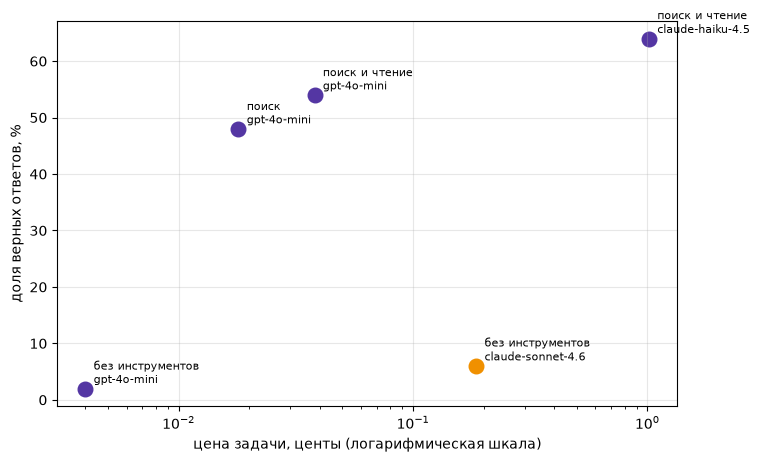

In [175]:
money_chart(table, path=IMG / "homework.png");

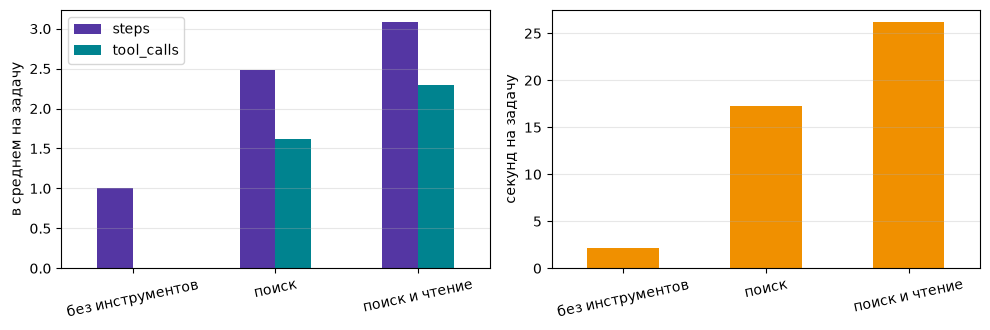

In [176]:
steps_chart(results[results["model"] == "gpt-4o-mini"]);

In [178]:
trace = json.loads(next((TRACES / "поиск и чтение" / "gpt-4o-mini").glob("custom-2026-*.json")).read_text(encoding="utf-8"))
show_trace(Run(trace["task"]["question"], trace["answer"], sum(m["role"] == "assistant" for m in trace["messages"]), trace["messages"], trace["cost"]))

user     | Which album won Best Alternative Music Album at the 2026 Grammy Awards? 
assistant|  ddg_search{"query":"2026 Grammy Awards Best Alternative Music Album winner"}
tool     | 1. Grammy Award for Best Alternative Music Album - Wikipedia URL: https://en.wikipedia.org/wiki/Grammy_Award_for_Best_Alternative_Music_Album As of 2025, Radiohead, The White Strip 
assistant|  read_page{"url":"https://www.grammy.com/awards/categories/best-alternative-music-album/2026/","keywords":"winner"}
tool     | Winners & Nominees 2026 Winner | Year | Winner | Title | | 
assistant|  read_page{"url":"https://www.altpress.com/grammys-2026-winners-alternative-rock-metal/","keywords":"winner"}
tool     | ошибка загрузки страницы: 403 Client Error: Forbidden for url: https://www.altpress.com/grammys-2026-winners-alternative-rock-metal/ 
assistant|  read_page{"url":"https://en.wikipedia.org/wiki/Grammy_Award_for_Best_Alternative_Music_Album","keywords":"2026 winner"}
tool     | | Currently held by | The C

In [179]:
ledger.table(), round(ledger.total, 3)

(                          calls  prompt  completion     cost  seconds
 tag    model                                                         
 agent  claude-haiku-4.5     166  429354       15604  0.50737   410.06
        claude-sonnet-4.6     50    6287        4939  0.09295   171.89
        gpt-4o-mini          365  196764       12946  0.03426   669.22
 struct gpt-4o-mini            2     247          45  0.00006     4.74,
 0.635)

In [180]:
results.loc[
    (results["config"] == "поиск и чтение")
    & (results["model"] == "gpt-4o-mini")
    & (~results["correct"]),
    ["id", "answer", "gold"],
]

,id,answer,gold
153,custom-2026-03,Информация недоступна.,Kimi Antonelli
154,custom-2026-04,Информация недоступна.,Kimi Antonelli
158,custom-2026-08,Неизвестно.,Charles Leclerc
161,custom-2026-11,Макс Ферстаппен,Max Verstappen
165,custom-2026-15,Информация недоступна.,Charles Leclerc
166,custom-2026-16,"Sebastian Vettel: 5, Lewis Hamilton: 5, Fernan...",4
167,custom-2026-17,50,50 years
168,custom-2026-18,10,10 years
169,custom-2026-19,9 years,nine years
170,custom-2026-20,30,30 years


In [183]:
path = TRACES / "поиск и чтение" / "gpt-4o-mini" / "custom-2026-15.json"
trace = json.loads(path.read_text(encoding="utf-8"))
trace

{'task': {'id': 'custom-2026-15',
  'source': 'fresh',
  'question': 'Who was voted Driver of the Day at the 2026 British Grand Prix?',
  'answer': 'Charles Leclerc',
  'evidence': 'Great Britain | Charles Leclerc LEC',
  'page': '2026 Salesforce Driver of the Day Award',
  'url': 'https://www.formula1.com/en/results/2026/awards/driver-of-the-day',
  'sonnet_answer': '',
  'agent_ok': False},
 'answer': 'Я не смог найти информацию о том, кто был назван "Водителем дня" на Британском Гран-при 2026 года. Возможно, эта информация еще не опубликована или доступна в ограниченных источниках. \n\nFINAL: Информация недоступна.',
 'correct': False,
 'cost': 0.0004008000000000067,
 'messages': [{'role': 'system',
   'content': 'Ты решаешь задачи. Если нужно посчитать или найти факт, вызывай инструменты, а не угадывай. Когда ответ готов, напиши его последней строкой в формате FINAL: <ответ>. Для числовых задач в FINAL только число, для вопросов о фактах короткая фраза.'},
  {'role': 'user',
   'co

In [184]:
path = TRACES / "поиск и чтение" / "gpt-4o-mini" / "custom-2026-11.json"
trace = json.loads(path.read_text(encoding="utf-8"))
trace

{'task': {'id': 'custom-2026-11',
  'source': 'fresh',
  'question': 'Who set the fastest lap at the 2026 Australian Grand Prix?',
  'answer': 'Max Verstappen',
  'evidence': 'Australia | Max Verstappen VER | 1:22.091',
  'page': '2026 DHL Fastest Lap Award',
  'url': 'https://www.formula1.com/en/results/2026/awards/fastest-laps',
  'sonnet_answer': '',
  'agent_ok': False},
 'answer': 'На Гран-при Австралии 2026 года быстрейший круг установил Макс Ферстаппен (Red Bull Racing) с результатом 1:22.091. \n\nFINAL: Макс Ферстаппен',
 'correct': False,
 'cost': 0.00015749999999999098,
 'messages': [{'role': 'system',
   'content': 'Ты решаешь задачи. Если нужно посчитать или найти факт, вызывай инструменты, а не угадывай. Когда ответ готов, напиши его последней строкой в формате FINAL: <ответ>. Для числовых задач в FINAL только число, для вопросов о фактах короткая фраза.'},
  {'role': 'user',
   'content': 'Who set the fastest lap at the 2026 Australian Grand Prix?'},
  {'role': 'assistant